# Quantile-Conditioned Least Squares Recommender — with an independent response model and a separate SVD model

**Group 3:** Millet, Solomon, Vrba, Yinzime

Problem statement: $\mathbf r_u = Z\theta^*_u + \epsilon_u$

In [6]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- configuration ---------------------------------------------------------
N_BINS    = 10          # B, popularity quantile bins (deciles)
N_USERS   = 400         # synthetic users
SEED      = 7
TOP_K     = 10          # K for NDCG@K
TARGET_COLUMN = "song_popularity"   # popularity score (0-100) used for the quantile bins

# Change only these two lists to experiment with a different feature set.
FEATURES    = ["song_duration_ms", "acousticness", "danceability", "energy", "instrumentalness",
               "liveness", "loudness", "speechiness", "tempo", "audio_valence",
               "audio_mode"]                      # numeric columns (audio_mode is already 0/1)
CATEGORICAL = ["key"]                             # columns that are labels, not quantities

## Data cleaning with the new songs.csv dataset
Rows with missing or non-numeric values in the configured columns are dropped, and so are exact duplicate rows (the file contains about 3,900 repeats).

In [7]:
CSV = next(p for p in [Path("song_data.csv"), Path("/mnt/user-data/uploads/song_data.csv")] if p.exists())
raw = pd.read_csv(CSV)
required_columns = [TARGET_COLUMN] + FEATURES + CATEGORICAL
missing_columns = [column for column in required_columns if column not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing configured columns: {missing_columns}")

for column in required_columns:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")
df = raw.dropna(subset=required_columns).drop_duplicates().reset_index(drop=True)

print(f"{len(raw)} rows read, {len(raw) - len(df)} dropped -> N = {len(df)} tracks")
display_columns = [column for column in ["song_name", "track_name"] if column in df.columns]
df[display_columns + [TARGET_COLUMN] + FEATURES + CATEGORICAL].head()

18835 rows read, 3909 dropped -> N = 14926 tracks


,song_name,song_popularity,song_duration_ms,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,audio_valence,audio_mode,key
0,Boulevard of Broken Dreams,73,262333,0.005520,0.496,0.682,0.000029,0.0589,-4.095,0.0294,167.060,0.474,1,8
1,In The End,66,216933,0.010300,0.542,0.853,0.000000,0.1080,-6.407,0.0498,105.256,0.370,0,3
2,Seven Nation Army,76,231733,0.008170,0.737,0.463,0.447000,0.2550,-7.828,0.0792,123.881,0.324,1,0
3,By The Way,74,216933,0.026400,0.451,0.970,0.003550,0.1020,-4.938,0.1070,122.444,0.198,1,0
4,How You Remind Me,56,223826,0.000954,0.447,0.766,0.000000,0.1130,-5.065,0.0313,172.011,0.574,1,10


## Quantile-conditioned design matrix $Z$ 

Implementation notes:

* What if there is a tie? $\hat F_S(S_i)$ is computed with `side="right"` (number of tracks with $S_k\le S_i$), as in the definition. With ties, bins are then not perfectly equal-sized.
* If a feature has zero variance inside a bin, $\sigma^{(b)}_j=0$ and the z-score is undefined. We set $\sigma^{(b)}_j:=1$ in that case, so $z=0$ there.
* Columns listed in `CATEGORICAL` (here `key`, values 0-11) are encoded with the first level dropped, then treated like any other column. `make_X` builds the feature matrix for any set of tracks, so new tracks get the same columns.

In [8]:
class QuantileConditioned:
    '''Fit on a catalogue (streams, X); transform any tracks (Appendix B).'''
    def __init__(self, n_bins=10, eps=1e-8):
        self.B, self.eps = n_bins, eps

    # --- popularity quantile and bin ------------------------------------------------
    def quantile(self, streams):
        return np.searchsorted(self.s_sorted_, streams, side="right") / self.N_      # F_hat(S)

    def bins(self, streams):
        b = np.ceil(self.B * self.quantile(streams)).astype(int)
        return np.clip(b, 1, self.B)                                                  # min{ceil(BQ), B}, >=1 for unseen tracks

    def standardize(self, X):
        return (X - self.mu_) / self.sd_

    # --- fit / transform -----------------------------------------------------------
    def fit(self, streams, X):
        streams, X = np.asarray(streams, float), np.asarray(X, float)
        self.N_, d = len(streams), X.shape[1]
        self.s_sorted_ = np.sort(streams)
        self.mu_, self.sd_ = X.mean(0), X.std(0)
        self.sd_[self.sd_ < self.eps] = 1.0
        Xt, b = self.standardize(X), self.bins(streams)

        self.n_bin_  = np.zeros(self.B, int)
        self.mu_bin_ = np.zeros((self.B, d))
        self.sd_bin_ = np.ones((self.B, d))
        for k in range(1, self.B + 1):
            sel = b == k
            self.n_bin_[k - 1] = sel.sum()
            if sel.sum() >= 2:
                self.mu_bin_[k - 1] = Xt[sel].mean(0)
                sd = Xt[sel].std(0)
                sd[sd < self.eps] = 1.0                    # degenerate bin/feature guard
                self.sd_bin_[k - 1] = sd
        return self

    def transform(self, streams, X):
        Xt, b = self.standardize(np.asarray(X, float)), self.bins(np.asarray(streams, float))
        return (Xt - self.mu_bin_[b - 1]) / self.sd_bin_[b - 1]


# columns are defined from the catalogue (first level dropped as the reference)
DUMMY_COLS = (pd.get_dummies(df[CATEGORICAL], columns=CATEGORICAL, drop_first=True, dtype=float).columns
              if CATEGORICAL else pd.Index([]))

def make_X(frame):
    '''Feature matrix (before conditioning) for any tracks: numeric columns + one-hot columns.'''
    X = frame[FEATURES].astype(float)
    if CATEGORICAL:
        dummies = pd.get_dummies(frame[CATEGORICAL], columns=CATEGORICAL, dtype=float)
        X = pd.concat([X, dummies.reindex(columns=DUMMY_COLS, fill_value=0.0)], axis=1)
    return X

FEATURE_NAMES = list(make_X(df).columns)
X_raw   = make_X(df).to_numpy(float)
streams = df[TARGET_COLUMN].to_numpy(float)      # popularity score/streams 
N, d    = X_raw.shape

cond  = QuantileConditioned(N_BINS).fit(streams, X_raw)
Z_all = cond.transform(streams, X_raw)          # N x d, the deck's design matrix
Xt_all = cond.standardize(X_raw)                # globally standardized features (unconditioned design)

print("Z shape:", Z_all.shape)
print("columns:", FEATURE_NAMES)
print("bin sizes:", cond.n_bin_)
print("max |column mean of Z|:", np.abs(Z_all.mean(0)).max().round(12))

Z shape: (14926, 22)
columns: ['song_duration_ms', 'acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'audio_valence', 'audio_mode', 'key_1', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'key_10', 'key_11']
bin sizes: [1464 1410 1496 1474 1545 1350 1548 1499 1446 1694]
max |column mean of Z|: 0.0


**Diagnostic from the deck:** *does $\mu^{(b)}_j$ vary across $b$?* If not, conditioning adds nothing. (After conditioning the bin means of $Z$ are 0 by construction, so the check must be done on the globally standardized features $\tilde x$.)

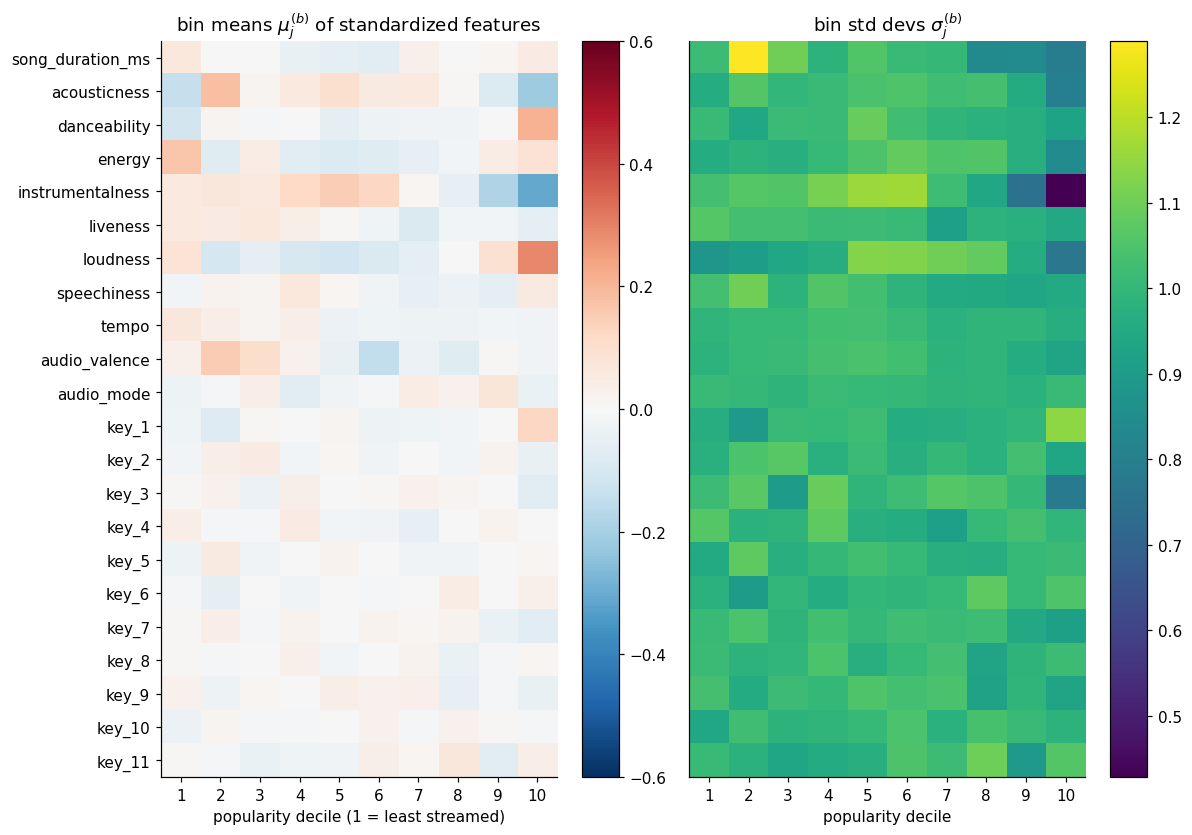

,range of bin means (std. units)
song_duration_ms,0.128
acousticness,0.393
danceability,0.315
energy,0.248
instrumentalness,0.455
liveness,0.150
loudness,0.403
speechiness,0.113
tempo,0.104
audio_valence,0.300


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, max(3.8, 0.35 * d)))
im = ax[0].imshow(cond.mu_bin_.T, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax[0].set_xticks(range(N_BINS)); ax[0].set_xticklabels(range(1, N_BINS + 1))
ax[0].set_yticks(range(d)); ax[0].set_yticklabels(FEATURE_NAMES)
ax[0].set_xlabel("popularity decile (1 = least streamed)"); ax[0].set_title(r"bin means $\mu_j^{(b)}$ of standardized features")
plt.colorbar(im, ax=ax[0])

im = ax[1].imshow(cond.sd_bin_.T, cmap="viridis", aspect="auto")
ax[1].set_xticks(range(N_BINS)); ax[1].set_xticklabels(range(1, N_BINS + 1)); ax[1].set_yticks([])
ax[1].set_xlabel("popularity decile"); ax[1].set_title(r"bin std devs $\sigma_j^{(b)}$")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

spread = pd.Series(cond.mu_bin_.max(0) - cond.mu_bin_.min(0), index=FEATURE_NAMES, name="range of bin means (std. units)")
spread.round(3).to_frame()

## SVD models (kept separate from the LS code)

### a. `ZSVD` — SVD of the design matrix

With $Z=U\Sigma V^\top$, the ridge solution for *all users at once* is
$$\hat\Theta^{\text{ridge}}=V\,\text{diag}\!\Big(\tfrac{\sigma_k}{\sigma_k^2+\lambda}\Big)U^\top R^\top,$$
which equals $(Z^\top Z+\lambda I)^{-1}Z^\top R^\top$ but never forms $Z^\top Z$ (squaring the condition number). It also gives the condition number $\kappa(Z)=\sigma_1/\sigma_d$ and the effective degrees of freedom $\sum_k \sigma_k^2/(\sigma_k^2+\lambda)$, which the deck's multicollinearity discussion needs.

In [10]:
class ZSVD:
    '''Thin SVD of a design matrix with stable ridge solves.'''
    def fit(self, Z):
        self.U_, self.s_, self.Vt_ = np.linalg.svd(Z, full_matrices=False)
        return self

    @property
    def condition_number(self):
        return self.s_[0] / self.s_[-1]

    def effective_df(self, lam):
        return np.sum(self.s_**2 / (self.s_**2 + lam))

    def solve(self, Y, lam=0.0):
        '''Y: N x U responses (one column per user)  ->  Theta: d x U'''
        filt = self.s_ / (self.s_**2 + lam)
        return self.Vt_.T @ (filt[:, None] * (self.U_.T @ Y))


# --- diagnostics for the design matrix -------------------------------------------------
zs = ZSVD().fit(Z_all)
print("singular values of Z :", zs.s_.round(1))
print(f"condition number kappa(Z) = {zs.condition_number:.2f}   (kappa(Z'Z) = {zs.condition_number**2:.2f})")

singular values of Z : [203.1 148.1 139.3 132.5 129.5 128.4 128.  127.3 127.  127.  126.7 125.2
 124.5 120.2 116.  114.7 111.9 103.9  91.6  76.7  48.3  43.4]
condition number kappa(Z) = 4.68   (kappa(Z'Z) = 21.87)


We see that the condition number of $Z$ is 4.68 which is pretty low, so we can say that this is a well-conditioned matrix. This means that when we use $Z$ in our further analyses it will not produce a lot of errors in the solutions (i.e. it is numerically stable so numerical solutions will be pretty accurate) 